# 02 · Exploratory analysis

Questions for the operations manager:
1. When does demand happen, and how different are weekdays and weekends?
2. How much do rain and temperature move demand?
3. Which stations are busiest, and do they behave differently (commuter hub vs park)?
4. Where do stations gain or lose bikes, which drives the rebalancing need?

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
from plotting import set_style, save, SERIES, INK, INK_2, NEUTRAL, BLUE_RAMP
set_style()
import features, db
journeys = pd.read_parquet('../data/processed/journeys_clean.parquet', columns=['start_ts', 'start_hour', 'bike_model', 'duration_s'])
df = features.build_feature_table(); features.save_feature_table(df)
df = df[df['is_outage'] == 0]
print(f'{len(journeys):,} journeys; feature table {df.shape}')

8,977,953 journeys; feature table (349440, 30)


## 1. Hourly pattern: weekday vs weekend

Weekday AM peak (07-09) share of weekday trips: 24.9%


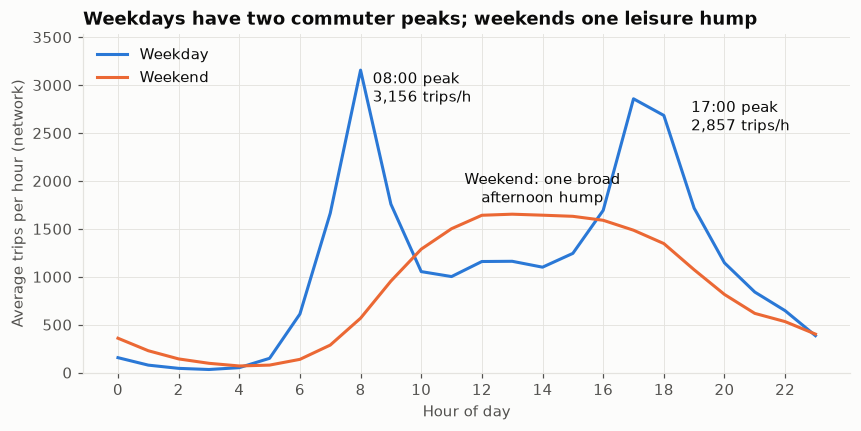

In [2]:
j = journeys.assign(hour=journeys['start_ts'].dt.hour, date=journeys['start_ts'].dt.normalize(),
                   weekend=journeys['start_ts'].dt.day_of_week >= 5)
prof = j.groupby(['weekend', 'hour']).size() / j.groupby('weekend')['date'].nunique()
prof = prof.unstack(0)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(prof.index, prof[False], color=SERIES[0], label='Weekday')
ax.plot(prof.index, prof[True], color=SERIES[1], label='Weekend')
ax.text(8.4, prof.loc[8, False], f"08:00 peak\n{prof.loc[8, False]:,.0f} trips/h", color=INK, va='top')
ax.text(18.9, prof.loc[17, False], f"17:00 peak\n{prof.loc[17, False]:,.0f} trips/h", color=INK, va='top')
ax.set_ylim(0, prof.values.max() * 1.12)
ax.text(14, prof.loc[14, True] + 80, 'Weekend: one broad\nafternoon hump', color=INK, ha='center', va='bottom')
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('Hour of day'); ax.set_ylabel('Average trips per hour (network)')
ax.set_title('Weekdays have two commuter peaks; weekends one leisure hump'); ax.legend(loc='upper left')
save(fig, '02_hourly_weekday_weekend');
print('Weekday AM peak (07-09) share of weekday trips:', f"{prof.loc[7:9, False].sum() / prof[False].sum():.1%}")

Busiest month / quietest month: 1.61x


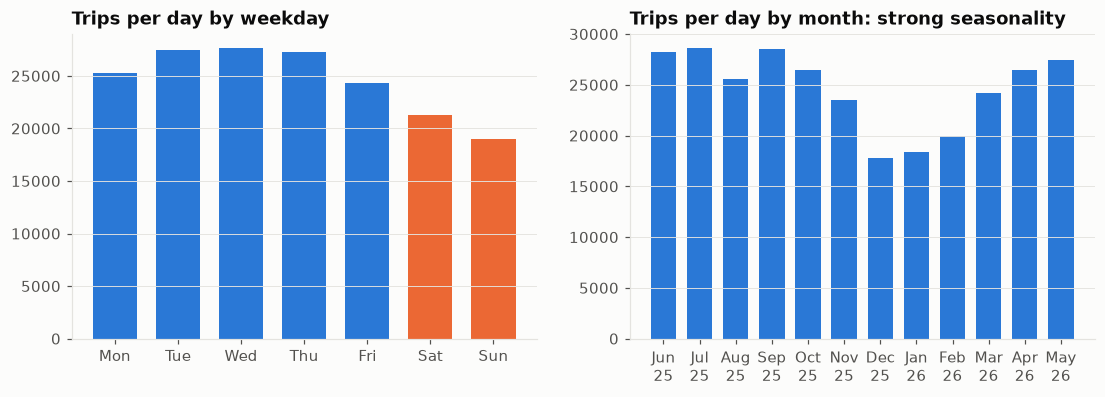

In [3]:
dow = j.groupby(j['start_ts'].dt.day_name()).size() / j.groupby(j['start_ts'].dt.day_name())['date'].nunique()
mon = j.groupby(j['start_ts'].dt.to_period('M')).size() / j.groupby(j['start_ts'].dt.to_period('M'))['date'].nunique()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
axes[0].bar(range(7), dow[order].values, color=[SERIES[0]]*5 + [SERIES[1]]*2, width=0.7)
axes[0].set_xticks(range(7), [d[:3] for d in order]); axes[0].set_title('Trips per day by weekday'); axes[0].grid(axis='x', visible=False)
axes[1].bar(range(len(mon)), mon.values, color=SERIES[0], width=0.7)
axes[1].set_xticks(range(len(mon)), [p.strftime('%b\n%y') for p in mon.index]); axes[1].set_title('Trips per day by month: strong seasonality'); axes[1].grid(axis='x', visible=False)
save(fig, '02_dow_month');
print(f"Busiest month / quietest month: {mon.max()/mon.min():.2f}x")

## 2. Weather effects

To isolate weather from time of day and season, each station-hour is compared with its **expected dry-weather demand** for the same station, hour, day type and month. A ratio of 0.7 means 30% fewer trips than a comparable dry hour.

,actual,expected,hours,ratio
rain_bin,,,,
Dry,1008956.0,1.008956e+06,196524,1.000000
0-0.5,134793.0,1.613887e+05,31302,0.835207
0.5-1,12745.0,1.796437e+04,4256,0.709460
1-2,12588.0,1.855533e+04,3465,0.678403
2-4,5264.0,8.503322e+03,1713,0.619052
>4,948.0,1.292536e+03,230,0.733442


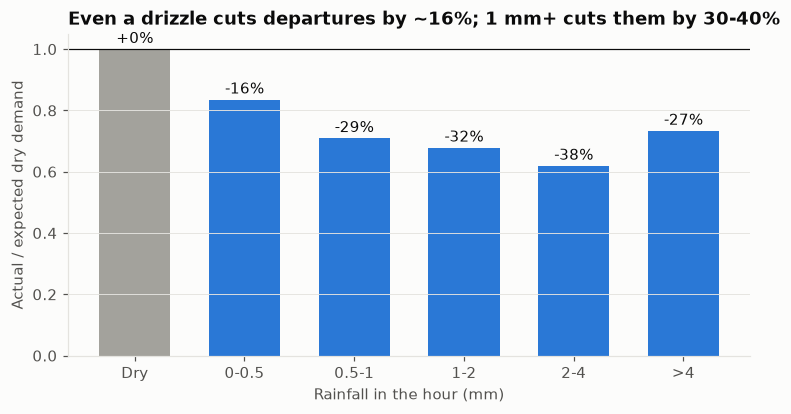

In [4]:
d = df.copy()
key = ['station_id', 'hour', 'is_weekend', 'month']
dry_mean = d[d['precipitation'] == 0].groupby(key)['departures'].mean().rename('dry_expected')
d = d.join(dry_mean, on=key)
d = d[d['dry_expected'] >= 1]  # avoid noisy ratios in near-empty night hours
bins = [-0.01, 0, 0.5, 1, 2, 4, 100]; labels = ['Dry', '0-0.5', '0.5-1', '1-2', '2-4', '>4']
d['rain_bin'] = pd.cut(d['precipitation'], bins, labels=labels)
rain = d.groupby('rain_bin', observed=True).agg(actual=('departures', 'sum'), expected=('dry_expected', 'sum'), hours=('departures', 'size'))
rain['ratio'] = rain['actual'] / rain['expected']
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(rain.index.astype(str), rain['ratio'], color=[NEUTRAL] + [SERIES[0]]*5, width=0.65)
for b, r, h in zip(bars, rain['ratio'], rain['hours']):
    ax.text(b.get_x() + b.get_width()/2, r + 0.02, f"{r-1:+.0%}", ha='center', color=INK)
ax.axhline(1, color=INK, lw=0.8)
ax.set_xlabel('Rainfall in the hour (mm)'); ax.set_ylabel('Actual / expected dry demand')
ax.set_title('Even a drizzle cuts departures by ~16%; 1 mm+ cuts them by 30-40%'); ax.grid(axis='x', visible=False)
save(fig, '02_rain_effect');
rain

Weekday: +547 trips/day per +1C
Weekend: +635 trips/day per +1C


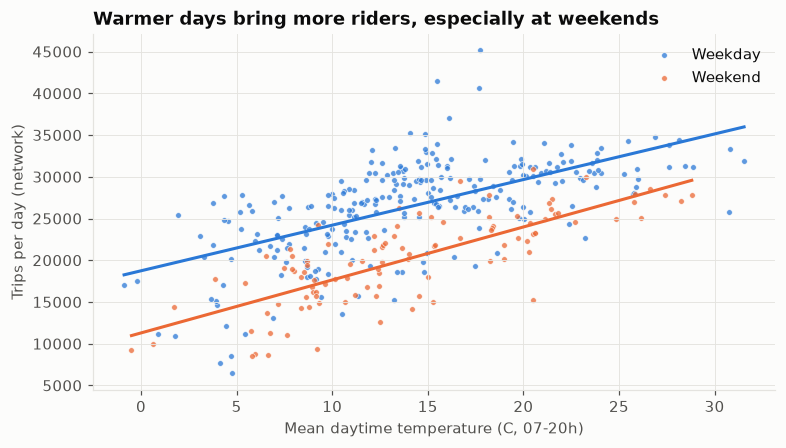

In [5]:
dd = j.groupby('date').agg(trips=('hour', 'size'), weekend=('weekend', 'first'))
w = features.load_weather(); w['date'] = w['hour_ts'].dt.normalize()
wd = w[w['hour_ts'].dt.hour.between(7, 20)].groupby('date').agg(temp=('temperature', 'mean'), rain=('precipitation', 'sum'))
dd = dd.join(wd).drop(pd.Timestamp('2025-08-05'))
fig, ax = plt.subplots(figsize=(8, 4.2))
for wk, c, lab in ((False, SERIES[0], 'Weekday'), (True, SERIES[1], 'Weekend')):
    s = dd[dd['weekend'] == wk]
    ax.scatter(s['temp'], s['trips'], s=14, color=c, alpha=0.75, label=lab, edgecolor='white', linewidth=0.5)
    z = np.polyfit(s['temp'], s['trips'], 1); xs = np.linspace(s['temp'].min(), s['temp'].max(), 2)
    ax.plot(xs, np.polyval(z, xs), color=c, lw=2)
    print(f"{lab}: +{z[0]:,.0f} trips/day per +1C")
ax.set_xlabel('Mean daytime temperature (C, 07-20h)'); ax.set_ylabel('Trips per day (network)')
ax.set_title('Warmer days bring more riders, especially at weekends'); ax.legend()
save(fig, '02_temperature_effect');

## 3. Busiest stations and their character

In [6]:
con = db.sqlite3.connect(db.DB_PATH)
prof_sql = pd.read_sql('SELECT * FROM station_profiles', con)
top = pd.read_sql('SELECT * FROM top_stations', con).merge(prof_sql[['station_id', 'share_am_peak', 'share_pm_peak', 'share_weekend', 'am_peak_net_flow_per_day']], on='station_id')
top[['demand_rank', 'display_name', 'nb_docks', 'departures_per_day', 'share_am_peak', 'share_pm_peak', 'share_weekend', 'am_peak_net_flow_per_day']].head(15)

,demand_rank,display_name,nb_docks,departures_per_day,share_am_peak,share_pm_peak,share_weekend,am_peak_net_flow_per_day
0,1,"Waterloo Station 3, Waterloo",35,162.5,0.757,0.033,0.036,-169.8
1,2,"Hyde Park Corner, Hyde Park",36,148.8,0.041,0.188,0.377,5.8
2,3,"Waterloo Station 1, Waterloo",36,123.3,0.497,0.099,0.118,-69.3
3,4,"Argyle Street, Kings Cross",45,107.8,0.372,0.122,0.179,-42.9
4,5,"Wormwood Street, Liverpool Street",15,105.2,0.238,0.322,0.129,6.2
5,6,"Albert Gate, Hyde Park",34,100.1,0.046,0.212,0.341,10.3
6,7,"Hop Exchange, The Borough",56,99.4,0.081,0.239,0.255,23.3
7,8,"Duke Street Hill, London Bridge",21,94.7,0.207,0.224,0.210,4.7
8,9,"Battersea Park Road, Nine Elms",27,93.6,0.139,0.202,0.284,9.2
9,10,"Black Lion Gate, Kensington Gardens",24,89.7,0.126,0.165,0.375,-9.5


**Classifying station character.** I first tried k-means on normalised 48-hour profiles. With k=3 it produced a lopsided 2 / 7 / 31 split that lumped King's Cross and London Bridge in with the parks. Explicit rules on the SQL profile metrics are easier to explain to operations and give a cleaner split. Applied in order:

| Type | Rule |
|---|---|
| Morning origin (rail hub / residential) | >= 30% of departures in the weekday 07-09 peak |
| Office / City (PM origin) | >= 30% in the weekday 16-18 peak **and** < 25% at weekends |
| Leisure / park | >= 30% of departures at weekends |
| Mixed | everything else |

In [7]:
def classify(r):
    if r['share_am_peak'] >= 0.30: return 'Morning origin'
    if r['share_pm_peak'] >= 0.30 and r['share_weekend'] < 0.25: return 'Office / City'
    if r['share_weekend'] >= 0.30: return 'Leisure / park'
    return 'Mixed'
top['station_type'] = top.apply(classify, axis=1)
types = top[['station_id', 'display_name', 'station_type', 'lat', 'lon', 'departures_per_day', 'nb_docks',
             'share_am_peak', 'share_pm_peak', 'share_weekend', 'am_peak_net_flow_per_day']]
types.to_csv('../data/processed/station_types.csv', index=False)
p = df.groupby(['station_id', 'is_weekend', 'hour'])['departures'].mean().unstack([1, 2])
p = p.div(p.sum(axis=1), axis=0)
for t, g in types.groupby('station_type'):
    print(f"{t} ({len(g)}): " + ', '.join(g.sort_values('departures_per_day', ascending=False)['display_name'].str.split(',').str[0].head(7)))

Leisure / park (7): Hyde Park Corner, Albert Gate, Black Lion Gate, Westminster Pier, Battersea Power Station, Islington Green, Serpentine Car Park
Mixed (19): Hop Exchange, Duke Street Hill, Battersea Park Road, Exhibition Road, Tooley Street, Old Street Station, London Street
Morning origin (5): Waterloo Station 3, Waterloo Station 1, Argyle Street, Eastbourne Mews, Eagle Wharf Road
Office / City (9): Wormwood Street, Brushfield Street, Soho Square , St. James's Square, Queen Street 2, Queen Street 1, Imperial College


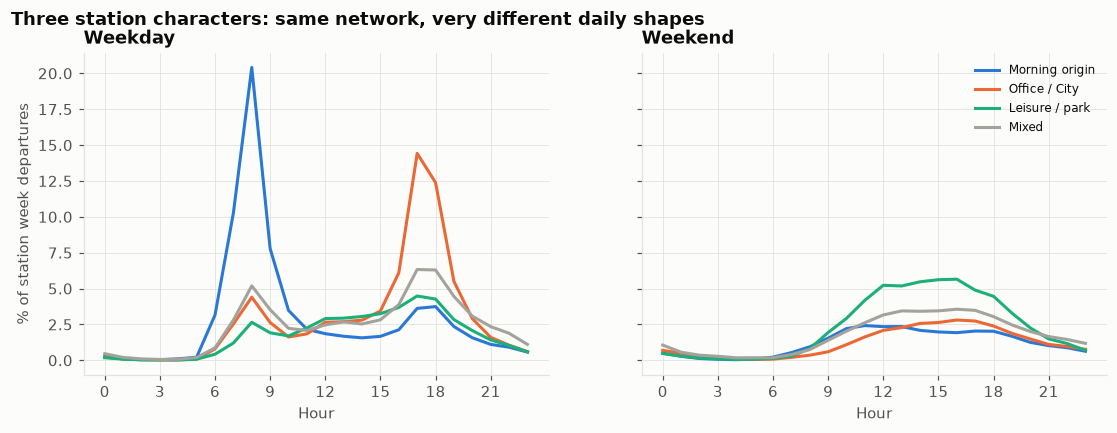

In [8]:
type_order = ['Morning origin', 'Office / City', 'Leisure / park', 'Mixed']
tcol = dict(zip(type_order, SERIES[:3] + [NEUTRAL]))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for wk, ax in zip((0, 1), axes):
    for t in type_order:
        ids = types.loc[types['station_type'] == t, 'station_id']
        ax.plot(range(24), p.loc[ids, [(wk, h) for h in range(24)]].mean().values * 100, color=tcol[t], label=t)
    ax.set_title('Weekday' if wk == 0 else 'Weekend'); ax.set_xticks(range(0, 24, 3)); ax.set_xlabel('Hour')
axes[0].set_ylabel('% of station week departures'); axes[1].legend(loc='upper right', fontsize=8)
fig.suptitle('Three station characters: same network, very different daily shapes', x=0.07, ha='left', fontweight='bold')
save(fig, '02_station_type_profiles');

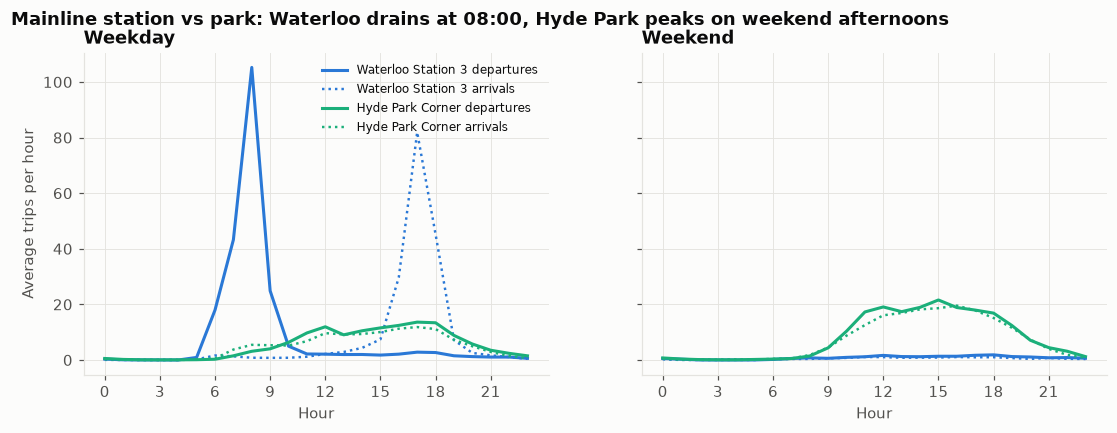

In [9]:
pair = {'Waterloo Station 3, Waterloo': SERIES[0], 'Hyde Park Corner, Hyde Park': SERIES[2]}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for wk, ax in zip((0, 1), axes):
    for name, col in pair.items():
        s = df[(df['display_name'] == name) & (df['is_weekend'] == wk)].groupby('hour')
        ax.plot(range(24), s['departures'].mean(), color=col, label=name.split(',')[0] + ' departures')
        ax.plot(range(24), s['arrivals'].mean(), color=col, ls=':', lw=1.6, label=name.split(',')[0] + ' arrivals')
    ax.set_title('Weekday' if wk == 0 else 'Weekend'); ax.set_xticks(range(0, 24, 3)); ax.set_xlabel('Hour')
axes[0].set_ylabel('Average trips per hour'); axes[0].legend(fontsize=8)
fig.suptitle('Mainline station vs park: Waterloo drains at 08:00, Hyde Park peaks on weekend afternoons', x=0.07, ha='left', fontweight='bold')
save(fig, '02_waterloo_vs_hydepark');

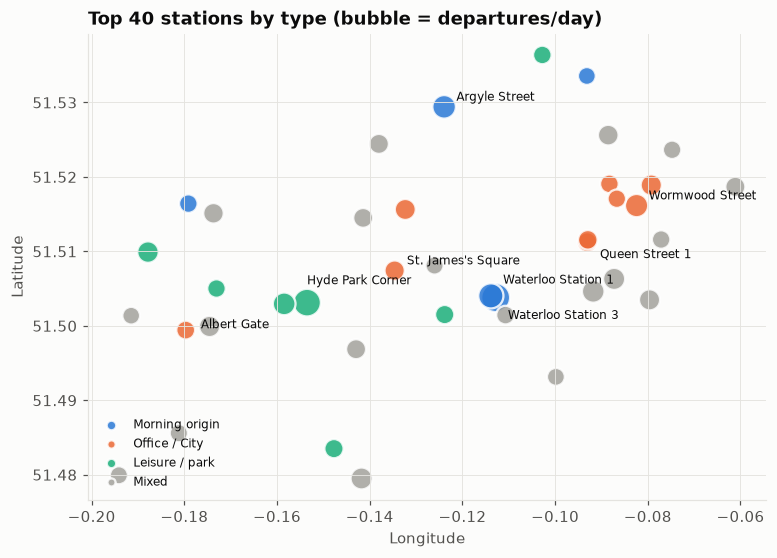

In [10]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for t in type_order:
    g = types[types['station_type'] == t]
    ax.scatter(g['lon'], g['lat'], s=g['departures_per_day'] * 2.2, color=tcol[t], alpha=0.85, edgecolor='white', linewidth=1.5, label=t)
offsets = {'Waterloo Station 3': (8, -14), 'Waterloo Station 1': (8, 8), 'Hyde Park Corner': (0, 12),
           'Albert Gate': (-10, -16), 'Argyle Street': (8, 4), 'Wormwood Street': (8, 4), 'Queen Street 1': (8, -12),
           "St. James's Square": (8, 4)}
for _, r in types.iterrows():
    short = r['display_name'].split(',')[0]
    if short in offsets:
        ax.annotate(short, (r['lon'], r['lat']), xytext=offsets[short], textcoords='offset points', fontsize=8, color=INK,
                    ha='right' if offsets[short][0] < 0 else 'left')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_aspect(1 / np.cos(np.radians(51.5)))
ax.set_title('Top 40 stations by type (bubble = departures/day)'); ax.legend(loc='lower left', fontsize=8, markerscale=0.4)
save(fig, '02_station_map');

## 4. Where do stations lose bikes? (net flow = arrivals − departures)

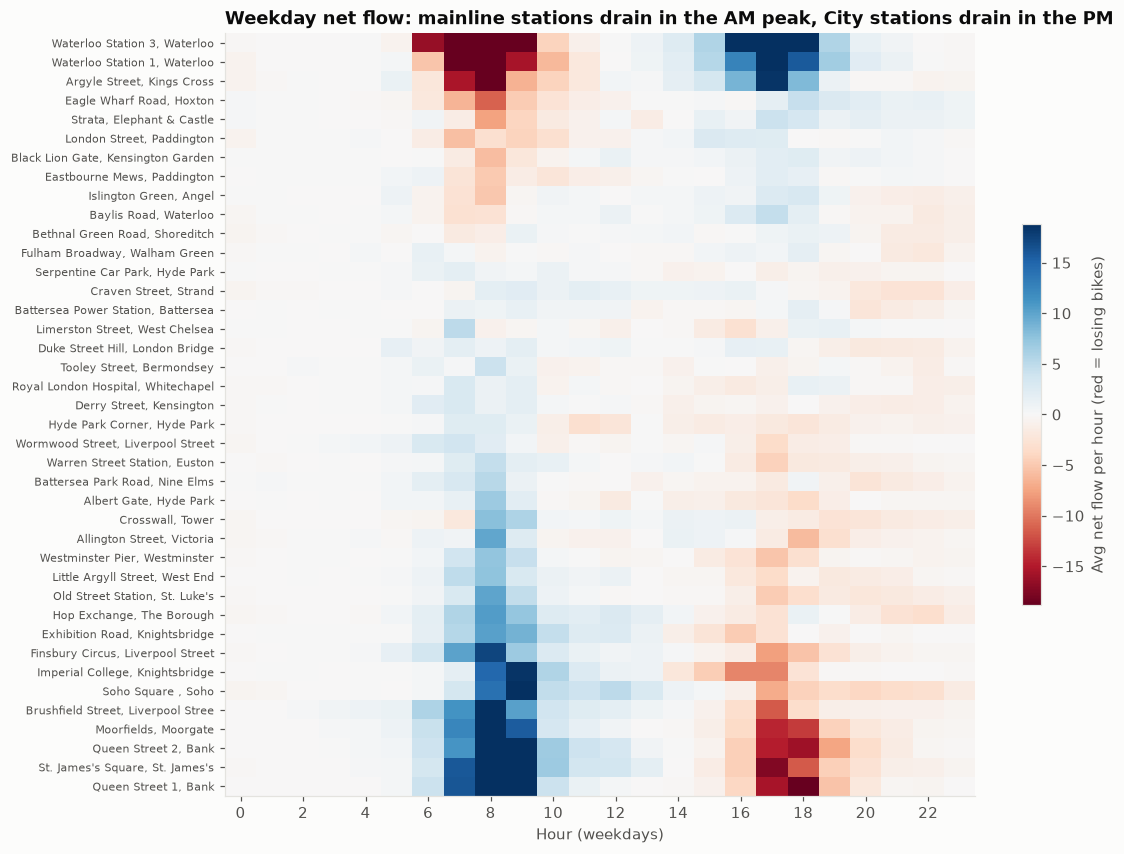

In [11]:
wkday = df[df['is_weekend'] == 0]
nf = (wkday.assign(net=wkday['arrivals'] - wkday['departures'])
          .pivot_table(index='display_name', columns='hour', values='net', aggfunc='mean'))
nf = nf.loc[nf[[7, 8, 9]].sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(11, 9))
lim = np.nanpercentile(np.abs(nf.values), 98)
im = ax.imshow(nf.values, cmap='RdBu', vmin=-lim, vmax=lim, aspect='auto')
ax.set_yticks(range(len(nf)), [n[:34] for n in nf.index], fontsize=7.5); ax.set_xticks(range(0, 24, 2)); ax.grid(False)
ax.set_xlabel('Hour (weekdays)')
cb = fig.colorbar(im, ax=ax, shrink=0.5); cb.set_label('Avg net flow per hour (red = losing bikes)')
ax.set_title('Weekday net flow: mainline stations drain in the AM peak, City stations drain in the PM')
save(fig, '02_net_flow_heatmap');

### EDA takeaways for the operations manager
* **Two different rebalancing problems.** *Morning-origin* docks (Waterloo, King's Cross, Paddington) lose bikes fast in the **07-09 weekday peak** as rail commuters ride on to work. Waterloo Station 3 has a net loss of about 170 bikes in that window on an average weekday, against 35 docks. *Office / City* docks (Bank, Moorgate, Liverpool St, St James's) do the reverse: they fill up in the morning (Queen Street 1 gains ~78 bikes) and empty in the **16-18 peak**.
* **Parks are a weekend problem.** Hyde Park, Kensington Gardens and the Serpentine peak on weekend afternoons, and much more so on warm days.
* **Weather matters.** Against comparable dry hours (same station, hour, day type and month), 0-0.5 mm of rain cuts departures by ~16%, and 1-4 mm by 30-40%. The >4 mm bucket is only 230 station-hours, mostly short summer downpours, so it is noisy. Each +1C of daytime temperature adds roughly 550 trips/day on weekdays and 635 at weekends across the network. A forecast that ignores weather will over-send vans on wet days.
* **Events.** The September Tube-strike week pushed network trips to the year's highs. This is the sort of demand shock a model with no event feature can't anticipate.